## Fase 1 — Preparación del entorno y preprocesamiento de datos

### 1.1 Configuración del entorno

In [1]:
!pip install -q spacy pysentimiento wordcloud
!python -m spacy download es_core_news_sm -q

✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [43]:
import json
import random
import re
import unicodedata
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import spacy
from IPython.display import Markdown, display
from matplotlib.gridspec import GridSpec
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from wordcloud import WordCloud

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

# Constantes de negocio y paleta compartida por todos los gráficos
PRODUCT_TG, PRODUCT_A, PRODUCT_B = "Auriculares TecnoGadget", "Competidor A", "Competidor B"
PRODUCT_ORDER = [PRODUCT_TG, PRODUCT_A, PRODUCT_B]
BRAND_SHORT = {PRODUCT_TG: "TecnoGadget", PRODUCT_A: "Competidor A", PRODUCT_B: "Competidor B"}
PRODUCT_COLORS = {PRODUCT_TG: "#264653", PRODUCT_A: "#e9c46a", PRODUCT_B: "#f4a261"}
SOURCE_ORDER = ["Amazon", "ForoX", "X", "ServicioCliente"]
SENT_ORDER = ["POS", "NEU", "NEG"]
SENT_COLORS = {"POS": "#2a9d8f", "NEU": "#adb5bd", "NEG": "#e76f51"}

# Stopwords: las de spaCy + palabras vacías propias de un texto legal
custom_stopwords = set(nlp.Defaults.stop_words) | {"artículo", "ley", "constitución", "español", "españa"}


def strip_accents(s):
    return "".join(c for c in unicodedata.normalize("NFD", s) if unicodedata.category(c) != "Mn")

def normalize_text(text):
    return unicodedata.normalize("NFKC", text) if isinstance(text, str) else ""


nlp = spacy.load("es_core_news_sm")
print("spaCy:", nlp.meta["name"], nlp.meta["version"])

# df desde Constitucion.txt
TXT_PATH = Path("Constitucion.txt")

# Lectura y limpieza del archivo
raw = TXT_PATH.read_text(encoding="utf-8-sig")                       # utf-8-sig
raw = raw[raw.find("\nPREÁMBULO\n"):].split("\nPOR TANTO,")[0]
raw = raw.replace("\f", "\n")
raw = "\n".join(l for l in raw.split("\n") if not re.fullmatch(r"\s*\d{1,3}\s*", l))
bloques = [re.sub(r"\s+", " ", b).strip() for b in re.split(r"\n\s*\n", raw) if b.strip()]


def es_nota_margen(b):
    return (len(b) < 90 and not re.search(r"[.;:,]$", b)
            and not re.match(r"^(T[ÍI]TULO|CAP[ÍI]TULO|SECCI[ÓO]N|DISPOSICI|Art[ií]culo|\d+\.|[a-z]\))", b))


# Recorrido secuencial: cada bloque es un encabezado, el nombre de un encabezado o texto de un artículo
ORDINALES = r"(Primera|Segunda|Tercera|Cuarta|Quinta|Sexta|Séptima|Octava|Novena|Décima|Única)"
SINGULAR = {"adicionales": "adicional", "transitorias": "transitoria"}
filas, titulo, nombre_titulo, capitulo, esperando, actual = [], "Preámbulo", "", "", None, None


def nueva_fila(articulo):
    fila = [articulo, titulo, nombre_titulo, capitulo, []]
    filas.append(fila)
    return fila


actual = nueva_fila("Preámbulo")
for b in bloques[1:]:                                                # bloques[0] es la palabra PREÁMBULO
    if m := re.fullmatch(r"T[ÍI]TULO (PRELIMINAR|[IVX]+)", b):
        titulo, nombre_titulo, capitulo, actual = f"Título {m[1].capitalize() if m[1] == 'PRELIMINAR' else m[1]}", "", "", None
        esperando = None if m[1] == "PRELIMINAR" else "titulo"
    elif m := re.fullmatch(r"CAP[ÍI]TULO (\w+)", b):
        capitulo, actual, esperando = f"Capítulo {m[1].capitalize()}", None, "ignorar"
    elif re.fullmatch(r"SECCI[ÓO]N \d+\.ª", b):
        actual, esperando = None, "ignorar"
    elif m := re.fullmatch(r"Art[ií]culo (\d+)\.?", b):
        actual, esperando = nueva_fila(f"Artículo {m[1]}"), None
    elif m := re.fullmatch(r"DISPOSICIONES (ADICIONALES|TRANSITORIAS)", b):
        titulo, nombre_titulo, capitulo, actual, esperando = f"Disposiciones {m[1].lower()}", "", "", None, None
    elif m := re.fullmatch(r"DISPOSICI[ÓO]N (DEROGATORIA|FINAL)", b):
        titulo, nombre_titulo, capitulo, esperando = f"Disposición {m[1].lower()}", "", "", None
        actual = nueva_fila(titulo)
    elif (m := re.fullmatch(ORDINALES + r"\.?", b)) and titulo.startswith("Disposiciones"):
        actual, esperando = nueva_fila(f"Disposición {SINGULAR[titulo.split()[1]]} {m[1].lower()}"), None
    elif esperando == "titulo":
        nombre_titulo, esperando = b, None
    elif esperando == "ignorar":
        esperando = None                                             # nombre de capítulo/sección
    elif actual is not None and not (actual[0] != "Preámbulo" and es_nota_margen(b)):
        actual[4].append(b)

df = pd.DataFrame([(f[0], f[1], f[2], f[3], " ".join(f[4])) for f in filas],
                  columns=["Articulo", "Titulo", "Nombre_Titulo", "Capitulo", "Texto_Comentario"])
df.insert(0, "ID", range(1, len(df) + 1))

df["Fuente"] = df["Titulo"]
df["Producto"] = "Constitución Española"
df["Puntuacion"] = 3
df = df[["ID", "Fuente", "Producto", "Puntuacion", "Texto_Comentario", "Articulo", "Titulo", "Nombre_Titulo", "Capitulo"]]

SOURCE_ORDER = list(df["Fuente"].unique())        # las celdas posteriores usan estas constantes
PRODUCT_ORDER = ["Constitución Española"]
PRODUCT_COLORS = {"Constitución Española": "#264653"}

print(f"Filas: {len(df)} | Columnas: {df.columns.tolist()}")
display(df.groupby("Fuente", sort=False).sample(1, random_state=SEED)[["ID", "Fuente", "Producto", "Puntuacion", "Texto_Comentario"]])

spaCy: core_news_sm 3.8.0
Filas: 185 | Columnas: ['ID', 'Fuente', 'Producto', 'Puntuacion', 'Texto_Comentario', 'Articulo', 'Titulo', 'Nombre_Titulo', 'Capitulo']


,ID,Fuente,Producto,Puntuacion,Texto_Comentario
0,1,Preámbulo,Constitución Española,3,"La Nación española, deseando establecer la justicia, la libertad y la seguridad y promover el bien de cuantos la int..."
8,9,Título Preliminar,Constitución Española,3,"1. Las Fuerzas Armadas, constituidas por el Ejército de Tierra, la Armada y el Ejército del Aire, tienen como misión..."
29,30,Título I,Constitución Española,3,"1. Todos los españoles tendrán el derecho de petición individual y colectiva, por escrito, en la forma y con los efe..."
64,65,Título II,Constitución Española,3,"1. Los actos del Rey serán refrendados por el Presidente del Gobierno y, en su caso, por los Ministros competentes. ..."
68,69,Título III,Constitución Española,3,"1. El Congreso se compone de un mínimo de 300 y un máximo de 400 Diputados, elegidos por sufragio universal, libre, ..."
98,99,Título IV,Constitución Española,3,"1. El Gobierno se compone del Presidente, de los Vicepresidentes en su caso, de los Ministros y de los demás miembro..."
111,112,Título V,Constitución Española,3,1. El Gobierno y cada uno de sus miembros están sometidos a las interpelaciones y preguntas que se le formulen en la...
119,120,Título VI,Constitución Española,3,"La justicia será gratuita cuando así lo disponga la ley, y, en todo caso, respecto de quienes acrediten insuficienci..."
135,136,Título VII,Constitución Española,3,1. Todas las Administraciones Públicas adecuarán sus actuaciones al principio de estabilidad presupuestaria. 2. El E...
149,150,Título VIII,Constitución Española,3,1. El Estado tiene competencia exclusiva sobre las siguientes materias: 1.o La regulación de las condiciones básicas...


### 1.2 Carga y validación del dataset
Si `Datos_TecnoGadget.csv` ya existe (por ejemplo, subido a Colab) se carga tal cual; si no, se genera y se guarda.

In [44]:
with open("Constitucion.txt", encoding="utf-8-sig") as f:
    text = f.read()
text = text[text.find("\nPREÁMBULO\n"):]
text = "\n".join(l for l in text.replace("\f", "\n").split("\n")
                 if not re.fullmatch(r"\s*\d{1,3}\s*", l))
text = re.sub(r"\s+", " ", text)
text = normalize_text(text)
doc = nlp(text)

processed_tokens = [t.lemma_.lower() for t in doc
                    if not t.is_stop and t.text.lower() not in custom_stopwords
                    and t.lemma_.lower() not in custom_stopwords
                    and t.is_alpha and not t.like_num]

word_freq = Counter(processed_tokens)
filtered_word_freq = {w: f for w, f in word_freq.items() if f >= 20}
print(f"Tokens: {len(processed_tokens)} | palabras con frecuencia >= 20: {len(filtered_word_freq)}")
print(word_freq.most_common(10))

Tokens: 7670 | palabras con frecuencia >= 20: 67
[('derecho', 134), ('gobierno', 91), ('público', 89), ('caso', 84), ('comunidades', 68), ('autónomas', 68), ('miembro', 55), ('congreso', 54), ('generales', 53), ('cortes', 51)]


,ID,Fuente,Producto,Puntuacion,Texto_Comentario,Articulo,Titulo,Nombre_Titulo,Capitulo
nulos,0,0,0,0,0,0,0,0,0
tipo,int64,object,object,int64,object,object,object,object,object


Textos duplicados: 0 (0.0%)


Fuente,Preámbulo,Título Preliminar,Título I,Título II,Título III,Título IV,Título V,Título VI,Título VII,Título VIII,Título IX,Título X,Disposiciones adicionales,Disposiciones transitorias,Disposición derogatoria,Disposición final,All
Producto,,,,,,,,,,,,,,,,,
Constitución Española,1,9,46,10,31,11,9,11,9,22,7,4,4,9,1,1,185
All,1,9,46,10,31,11,9,11,9,22,7,4,4,9,1,1,185


,count,mean,std
Producto,,,
Constitución Española,185,3.0,0.0


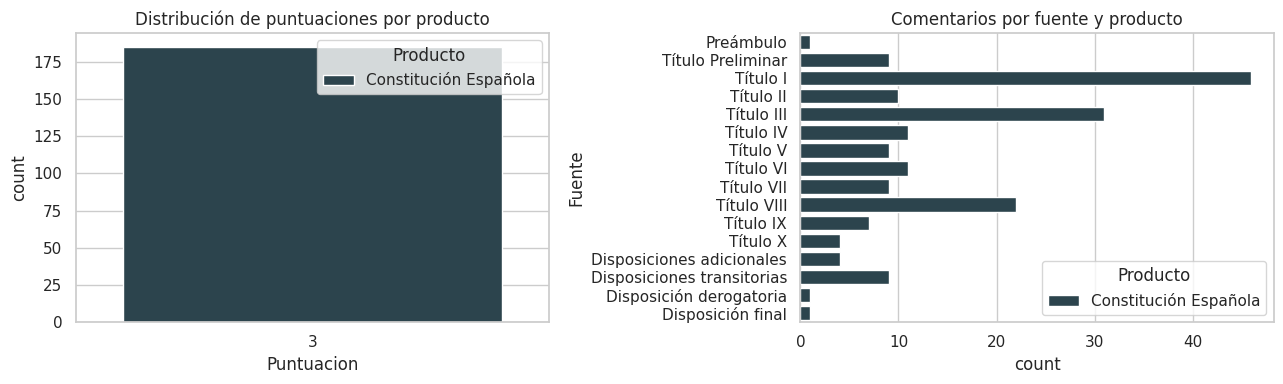

In [45]:
display(pd.DataFrame({"nulos": df.isna().sum(), "tipo": df.dtypes.astype(str)}).T)
print(f"Textos duplicados: {df['Texto_Comentario'].duplicated().sum()} "
      f"({df['Texto_Comentario'].duplicated().mean():.1%})")

display(pd.crosstab(df["Producto"], df["Fuente"], margins=True).reindex(columns=SOURCE_ORDER + ["All"]))
# Control de sesgo: el reparto de puntuaciones se compara solo en reseñas (el servicio solo atiende a TecnoGadget)
display(df[df["Fuente"] != "ServicioCliente"].groupby("Producto")["Puntuacion"].agg(["count", "mean", "std"]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df, x="Puntuacion", hue="Producto", hue_order=PRODUCT_ORDER, palette=PRODUCT_COLORS, ax=axes[0])
axes[0].set_title("Distribución de puntuaciones por producto")
sns.countplot(data=df, y="Fuente", order=SOURCE_ORDER, hue="Producto", hue_order=PRODUCT_ORDER,
              palette=PRODUCT_COLORS, ax=axes[1])
axes[1].set_title("Comentarios por fuente y producto")
plt.tight_layout(); plt.show()

In [46]:
INSTITUCIONES = ["Estado", "Cortes Generales", "Congreso de los Diputados", "Congreso", "Senado", "Gobierno", "Tribunal Constitucional",
                 "Tribunal Supremo", "Tribunal de Cuentas", "Consejo General del Poder Judicial", "Consejo de Estado",
                 "Defensor del Pueblo", "Ministerio Fiscal", "Fuerzas Armadas", "Fuerzas y Cuerpos de Seguridad",
                 "Comunidades Autónomas", "Comunidad Autónoma", "Corona", "Administración Local", "Ayuntamientos", "Diputaciones"]
CARGOS = ["Rey", "Reina", "Príncipe heredero", "Regente", "Presidente del Gobierno", "Presidente del Congreso", "Vicepresidente",
          "Ministros", "Diputados", "Senadores", "Magistrados", "Jueces"]

EMOJI_MAP = {"😍": " encanta ", "🔥": " genial ", "👍": " bien ", "💯": " perfecto ", "😊": " contento ",
             "😡": " enfadado ", "👎": " mal ", "😤": " harto ", "🙄": " decepcionante ", "😒": " decepcionado "}
EMOJI_RE = re.compile("[\U0001F300-\U0001FAFF\u2600-\u27BF\uFE0F]")
URL_RE = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")

NEGATION_WORDS = {"no", "nunca", "jamás", "jamas", "ni", "tampoco", "ningún", "ninguno", "ninguna", "nadie", "nada", "sin"}
SENTIMENT_KEEP = {"bien", "bueno", "buena", "buenos", "buenas", "buen", "mal", "mejor", "mejores", "peor", "peores",
                  "gran", "grande", "fatal", "mucho", "poco", "demasiado", "más", "menos"}
DOMAIN_STOPWORDS = {"auricular", "auriculares", "tecnogadget", "competidor", "tecnogadget_es", "producto", "ser", "estar",
                    "tener", "hacer", "ir", "poder", "haber", "dar", "ver", "llegar", "pasar",
                    "llamer", "abrí", "contacté", "escribí", "él",
                    # palabras muy frecuentes pero poco informativas en nubes y temas
                    "hora", "mes", "superar", "notar", "oir", "día", "vez", "cosa", "compra", "comprar", "recibir",
                    "probar", "trabajar", "quedar", "parecer", "llevar", "decir", "sentir", "pedir", "esperar",
                    "encontrar", "repetir", "conseguir"}

STOPWORDS = (set(nlp.Defaults.stop_words) - SENTIMENT_KEEP) | DOMAIN_STOPWORDS


def normalize_text(text):
    """NFKC preserva tildes, ñ y ü."""
    if not isinstance(text, str):
        return ""
    return unicodedata.normalize("NFKC", text)


def replace_emojis(text):
    for emoji, word in EMOJI_MAP.items():
        text = text.replace(emoji, word)
    return EMOJI_RE.sub(" ", text)


def clean_social(text):
    """Quita URLs y @menciones; deja el hashtag como palabra."""
    text = URL_RE.sub(" ", text)
    text = MENTION_RE.sub(" ", text)
    return re.sub(r"#(\w+)", r"\1", text)


def restore_accents(text):
    return CANON_RE.sub(lambda m: CANON[m.group(0).lower()], text)


def clean_light(text):
    """Limpieza mínima (NER y transformers): NFKC, sin URLs/menciones/emojis, espacios colapsados."""
    if not isinstance(text, str) or not text.strip():
        return ""
    text = EMOJI_RE.sub(" ", clean_social(normalize_text(text)))
    return re.sub(r"\s+", " ", text).strip()


def is_stop(tok):
    return tok["lower"] in STOPWORDS or tok["lemma"] in STOPWORDS


def handle_negations(tokens, window=3):
    """Une negación + siguiente palabra con contenido. Debe aplicarse ANTES de quitar stopwords."""
    out, i = [], 0
    while i < len(tokens):
        tok = tokens[i]
        if tok["lower"] in NEGATION_WORDS:
            j, target = i + 1, None
            while j < len(tokens) and j <= i + window and not tokens[j]["punct"]:
                if not is_stop(tokens[j]) and not tokens[j]["num"]:
                    target = j
                    break
                j += 1
            if target is not None:                      # par negado: "no_funcionar"
                out.append(f"{tok['lower']}_{tokens[target]['lemma']}")
                i = target + 1
            else:                                       # negación sin objetivo: se descarta
                i += 1
            continue
        out.append(tok)
        i += 1
    return out


def preprocess_corpus(texts):
    """Pipeline clásico: NFKC, emojis, limpieza, lematización, negaciones ANTES de stopwords."""
    prepared = []
    for t in texts:
        t = restore_accents(clean_social(replace_emojis(normalize_text(t)))).lower()
        prepared.append(re.sub(r"[^\w\sáéíóúüñ.,;:!?¿¡-]", " ", t))
    results = []
    for doc in nlp.pipe(prepared, batch_size=64, disable=["parser", "ner"]):
        toks = [{"lower": t.lower_,
                 "lemma": t.lower_ if t.lower_ in TAXONOMY_WORDS else (t.lemma_.lower().split() or [t.lower_])[0],
                 "punct": t.is_punct, "num": t.like_num} for t in doc if not t.is_space]
        final = []
        for t in handle_negations(toks):                # ANTES de stopwords
            if isinstance(t, str):                      # par negado: conservar
                final.append(t)
            elif not (t["punct"] or t["num"] or is_stop(t) or len(t["lemma"]) < 2):
                final.append(t["lemma"])
        results.append(final)
    return results


def tokenize_raw_text(text):
    return [t.text for t in nlp.make_doc(normalize_text(text)) if not t.is_space]

In [47]:
df["texto_limpio"] = df["Texto_Comentario"].apply(clean_light)
df["processed_tokens"] = preprocess_corpus(df["Texto_Comentario"])
display(df[["ID", "Texto_Comentario", "processed_tokens"]].sample(5, random_state=SEED))

,ID,Texto_Comentario,processed_tokens
19,20,"Los españoles tienen derecho a elegir libremente su residencia y a circular por el territorio nacional. Asimismo, ti...","[español, derecho, elegir, libremente, residencia, circular, territorio, nacional, asimismo, derecho, entrar, salir,..."
42,43,El Estado velará especialmente por la salvaguardia de los derechos económicos y sociales de los trabajadores español...,"[velar, especialmente, salvaguardia, derecho, económico, social, trabajador, español, extranjero, orientar, política..."
156,157,1. Las Comunidades Autónomas gozarán de autonomía financiera para el desarrollo y ejecución de sus competencias con ...,"[comunidad, autónomo, gozar, autonomía, financiero, desarrollo, ejecución, competencia, arreglo, principio, coordina..."
111,112,1. El Gobierno y cada uno de sus miembros están sometidos a las interpelaciones y preguntas que se le formulen en la...,"[gobierno, miembro, sometido, interpelación, pregunta, formulir, cámara, clase, debate, reglamento, establecer, tiem..."
148,149,1. Las Comunidades Autónomas podrán asumir competencias en las siguientes materias: 1.o Organización de sus instituc...,"[comunidad, autónomo, asumir, competencia, materia, 1.o, organización, institución, autogobierno, 2.o, alteración, t..."


### 1.4 Exploración inicial

,antes,después
Comentarios,185.00,185.00
Longitud media (tokens),104.06,40.39
Vocabulario único,2747.00,1836.00


antes                  después           
  index frecuencia         index frecuencia
0    de       1337           ley        201
1     .       1040       derecho        110
2     ,        901       público         91
3    la        827       general         91
4     y        659     comunidad         86
5    el        567      autónomo         80
6   los        543      gobierno         78
7    en        483          caso         74
8   las        447      artículo         65
9     a        363  constitución         59

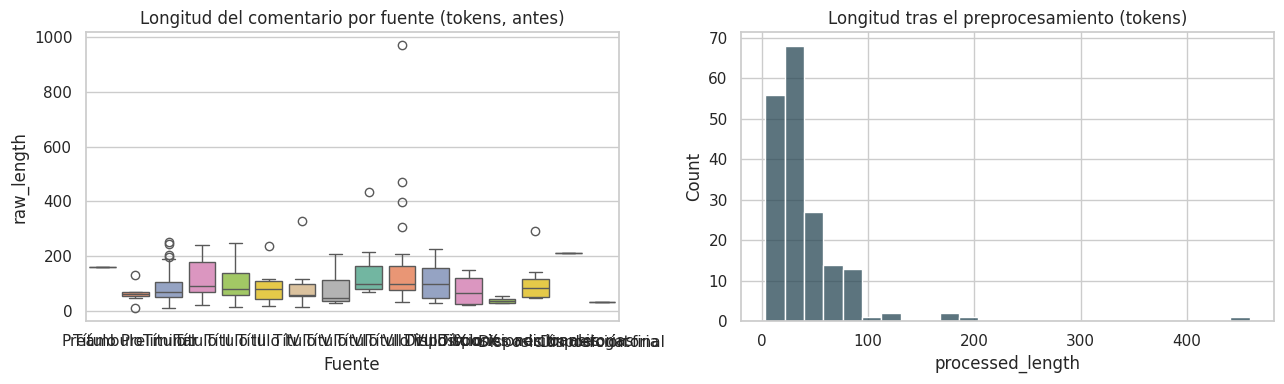

In [48]:
df["raw_tokens"] = df["Texto_Comentario"].apply(tokenize_raw_text)
df["raw_length"] = df["raw_tokens"].apply(len)
df["processed_length"] = df["processed_tokens"].apply(len)

raw_freq = Counter(t.lower() for toks in df["raw_tokens"] for t in toks)
proc_freq = Counter(t for toks in df["processed_tokens"] for t in toks)

display(pd.DataFrame({
    "antes": [len(df), df["raw_length"].mean().round(2), len(raw_freq)],
    "después": [len(df), df["processed_length"].mean().round(2), len(proc_freq)],
}, index=["Comentarios", "Longitud media (tokens)", "Vocabulario único"]))

top = pd.concat({"antes": pd.Series(dict(raw_freq.most_common(10))).rename("frecuencia").reset_index(),
                 "después": pd.Series(dict(proc_freq.most_common(10))).rename("frecuencia").reset_index()}, axis=1)
display(top)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x="Fuente", y="raw_length", order=SOURCE_ORDER, hue="Fuente", hue_order=SOURCE_ORDER,
            palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Longitud del comentario por fuente (tokens, antes)")
sns.histplot(df["processed_length"], bins=25, color="#264653", ax=axes[1])
axes[1].set_title("Longitud tras el preprocesamiento (tokens)")
plt.tight_layout(); plt.show()

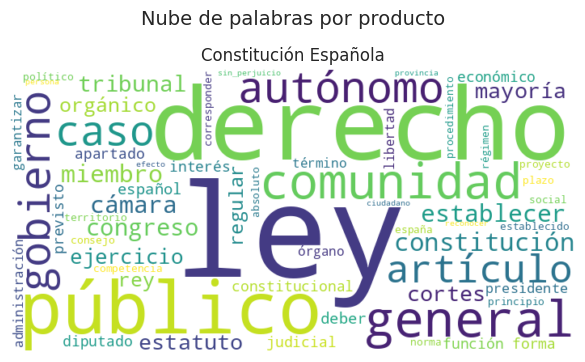

In [49]:
def plot_wordclouds(groups, title, ncols, min_freq=3):
    """Una nube de palabras por grupo {nombre: lista de tokens}."""
    nrows = int(np.ceil(len(groups) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6.2 * ncols, 3.6 * nrows))
    axes = np.array(axes).reshape(-1)
    for ax, (name, toks) in zip(axes, groups.items()):
        freq = {w: f for w, f in Counter(toks).items() if f >= min_freq}
        wc = WordCloud(width=700, height=350, background_color="white", colormap="viridis",
                       max_words=60, collocations=False).generate_from_frequencies(freq)
        ax.imshow(wc, interpolation="bilinear")
        ax.set_title(name)
        ax.axis("off")
    for ax in axes[len(groups):]:
        ax.axis("off")
    fig.suptitle(title, fontsize=14, y=1.0)
    plt.tight_layout(); plt.show()


tokens_by = lambda col, val: [t for toks in df.loc[df[col] == val, "processed_tokens"] for t in toks]
plot_wordclouds({p: tokens_by("Producto", p) for p in PRODUCT_ORDER}, "Nube de palabras por producto", ncols=1)

## Fase 2 — Análisis de sentimiento, entidades y temas

### 2.1 Análisis de sentimiento (polaridad general)

Se usa **`pysentimiento`** (modelo RoBERTa específico para español) sobre `clean_light`, no sobre los tokens lematizados: los transformers necesitan el texto natural. La **polaridad** es `P(POS) − P(NEG)` (de −1 a +1) y `sentiment_score` es la confianza de la clase elegida.

> En Colab conviene activar GPU (*Entorno de ejecución → Cambiar tipo → T4*). Con CPU tarda unos minutos más.

In [24]:
from pysentimiento import create_analyzer

analyzer = create_analyzer(task="sentiment", lang="es")


def predict_sentiment(texts, batch_size=64):
    """Devuelve (etiqueta, P(POS), P(NEU), P(NEG)) por texto, en lotes."""
    out = []
    for i in range(0, len(texts), batch_size):
        for r in analyzer.predict(texts[i:i + batch_size]):
            out.append((r.output.upper(), r.probas["POS"], r.probas["NEU"], r.probas["NEG"]))
    return out


sent = predict_sentiment(df["texto_limpio"].tolist())
df["sentiment_label"] = [s[0] for s in sent]
df["sentiment_score"] = [max(s[1:]) for s in sent]
df["polarity"] = [s[1] - s[3] for s in sent]

display(df[["ID", "Texto_Comentario", "sentiment_label", "sentiment_score", "polarity"]].head(8))
display(df["sentiment_label"].value_counts().reindex(SENT_ORDER).to_frame("comentarios"))

config.json:   0%|          | 0.00/925 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  435MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/384 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.31M [00:00<?, ?B/s]

... (3 outputs left out)

Map:   0%|          | 0/64 [00:00<?, ? examples/s]

Map:   0%|          | 0/57 [00:00<?, ? examples/s]

,ID,Texto_Comentario,sentiment_label,sentiment_score,polarity
0,1,"La Nación española, deseando establecer la justicia, la libertad y la seguridad y promover el bien de cuantos la int...",POS,0.506766,0.411311
1,2,"1. España se constituye en un Estado social y democrático de Derecho, que propugna como valores superiores de su ord...",NEU,0.514896,0.302729
2,3,"La Constitución se fundamenta en la indisoluble unidad de la Nación española, patria común e indivisible de todos lo...",POS,0.474713,0.371958
3,4,1. El castellano es la lengua española oficial del Estado. Todos los españoles tienen el deber de conocerla y el der...,POS,0.543413,0.507043
4,5,"1. La bandera de España está formada por tres franjas horizontales, roja, amarilla y roja, siendo la amarilla de dob...",NEU,0.805969,0.073950
5,6,La capital del Estado es la villa de Madrid.,NEU,0.584027,0.098060
6,7,"Los partidos políticos expresan el pluralismo político, concurren a la formación y manifestación de la voluntad popu...",POS,0.527303,0.458654
7,8,Los sindicatos de trabajadores y las asociaciones empresariales contribuyen a la defensa y promoción de los interese...,NEU,0.543006,0.200785


,comentarios
sentiment_label,
POS,6
NEU,172
NEG,7


### 2.2 Extracción de entidades nombradas (NER)


Entidades detectadas por el modelo: 1376 | tras validación: 1131


,entidades
etiqueta,
INSTITUCION,408
MISC,311
LOC,171
CARGO,122
ORG,69
PER,50


,más frecuentes
etiqueta,
CARGO,"rey (41), diputados (16), senadores (15), jueces (11), presidente del gobierno (10), ministros (9), magistrados (8),..."
INSTITUCION,"estado (84), gobierno (68), comunidades autónomas (56), cortes generales (42), congreso (32), comunidad autónoma (21..."
LOC,"españa (15), tribunales (10), las cámaras (10), la ley (9), administración (5), fiscales (4), administraciones públi..."
MISC,"la ley (18), estatutos (9), una ley orgánica (7), estatuto (6), estatutos de autonomía (5), presidente (4), estatuto..."
ORG,"consejo de (9), asamblea (5), seguridad social (4), presupuestos generales del (4), reglamento (3), tratados (3), pr..."
PER,"españa (3), sólo (3), presidente (3), legislación (3), hacienda (2), presupuestos (2), podrá (2), s. m. don juan car..."


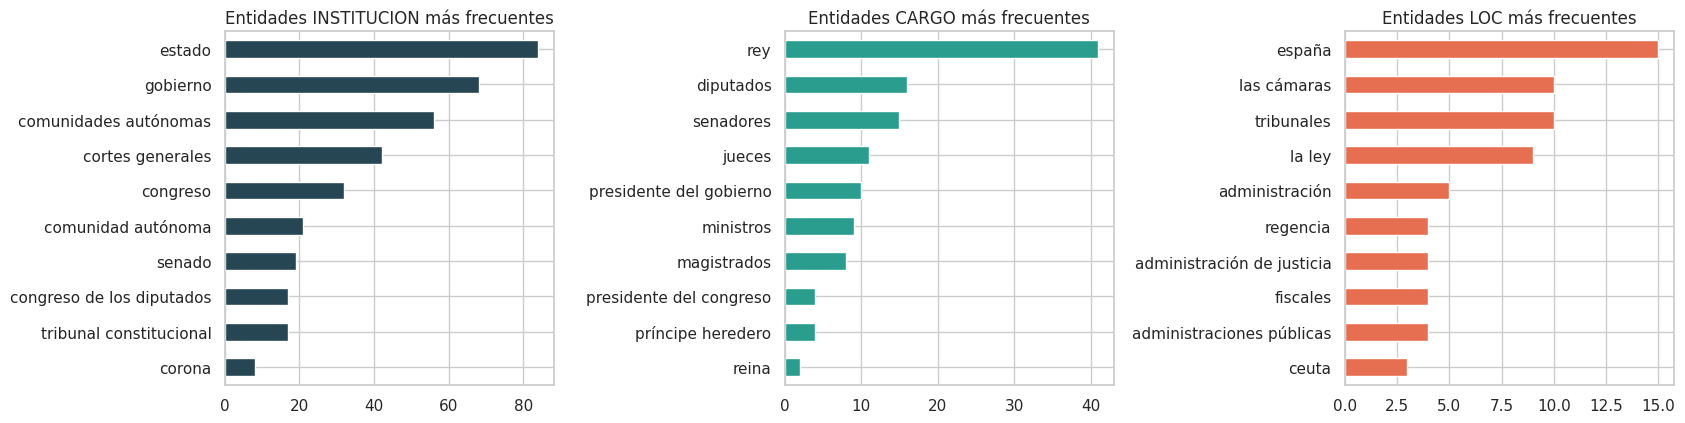

In [50]:
nlp_ner = spacy.load("es_core_news_sm")
ruler_ner = nlp_ner.add_pipe("entity_ruler", before="ner", config={"overwrite_ents": True})

patrones = ([{"label": "INSTITUCION", "pattern": [{"LOWER": t.lower_} for t in nlp_ner.make_doc(x)]} for x in INSTITUCIONES]
            + [{"label": "CARGO", "pattern": [{"LOWER": t.lower_} for t in nlp_ner.make_doc(x)]} for x in CARGOS])
ruler_ner.add_patterns(patrones)

docs_ner = list(nlp_ner.pipe(df["Texto_Comentario"], batch_size=32, disable=["parser", "lemmatizer", "morphologizer", "attribute_ruler"]))


def ent_valida(e):
    """Las entidades del EntityRuler se aceptan siempre. Las del modelo, solo si empiezan en mayúscula, no llevan números y no son palabras del propio texto legal."""
    if e.label_ in ("INSTITUCION", "CARGO"):
        return True
    return (e.text[:1].isupper() and not any(c.isdigit() for c in e.text) and len(e.text) > 2
            and e.text not in {"Constitución", "Ley", "Título", "Capítulo", "Artículo", "Cámara", "Cámaras"})


print("Entidades detectadas por el modelo:", sum(len(d.ents) for d in docs_ner), "| tras validación:", sum(ent_valida(e) for d in docs_ner for e in d.ents))
df["entidades"] = [[(e.text, e.label_) for e in d.ents if ent_valida(e)] for d in docs_ner]

ents_long = pd.DataFrame([(row.ID, row.Fuente, row.Articulo, ent, lab) for row in df.itertuples() for ent, lab in row.entidades],
                         columns=["ID", "Fuente", "Articulo", "entidad", "etiqueta"])
ents_long["entidad"] = ents_long["entidad"].str.lower()

display(ents_long["etiqueta"].value_counts().to_frame("entidades"))
top = ents_long.groupby("etiqueta")["entidad"].agg(lambda s: ", ".join(f"{k} ({v})" for k, v in s.value_counts().head(8).items()))
display(top.to_frame("más frecuentes"))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for ax, (lab, color) in zip(axes, [("INSTITUCION", "#264653"), ("CARGO", "#2a9d8f"), ("LOC", "#e76f51")]):
    ents_long.loc[ents_long["etiqueta"] == lab, "entidad"].value_counts().head(10).sort_values().plot(kind="barh", color=color, ax=ax)
    ax.set_title(f"Entidades {lab} más frecuentes"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

In [51]:
docs_ner = list(nlp.pipe(df["texto_limpio"], batch_size=64,
                         disable=["parser", "lemmatizer", "morphologizer", "attribute_ruler"]))

df["entidades"] = [[(e.text, e.label_) for e in d.ents] for d in docs_ner]

conteo = Counter(l for ents in df["entidades"] for _, l in ents)
display(pd.Series(conteo, name="entidades").sort_values(ascending=False).to_frame())
display(df[["ID", "texto_limpio", "entidades"]].loc[df["entidades"].str.len() > 2].head(5))

,entidades
LOC,552
MISC,434
ORG,180
PER,121


,ID,texto_limpio,entidades
0,1,"La Nación española, deseando establecer la justicia, la libertad y la seguridad y promover el bien de cuantos la int...","[(Nación, LOC), (Garantizar, MISC), (Constitución, LOC), (Consolidar, LOC), (Estado de Derecho, LOC), (Proteger, MIS..."
1,2,"1. España se constituye en un Estado social y democrático de Derecho, que propugna como valores superiores de su ord...","[(1, LOC), (España, LOC), (Estado social, ORG), (Derecho, PER), (La soberanía nacional, MISC), (Estado, LOC), (Estad..."
3,4,1. El castellano es la lengua española oficial del Estado. Todos los españoles tienen el deber de conocerla y el der...,"[(1, LOC), (El castellano, MISC), (Estado, LOC), (Comunidades Autónomas, PER), (Estatutos. 3, MISC), (España, LOC)]"
4,5,"1. La bandera de España está formada por tres franjas horizontales, roja, amarilla y roja, siendo la amarilla de dob...","[(1, LOC), (La bandera de España, MISC), (Los Estatutos podrán reconocer banderas, MISC), (Comunidades Autónomas, LO..."
8,9,"1. Las Fuerzas Armadas, constituidas por el Ejército de Tierra, la Armada y el Ejército del Aire, tienen como misión...","[(1, LOC), (Las Fuerzas Armadas, MISC), (Ejército de Tierra, LOC), (Armada, ORG), (Ejército del Aire, LOC), (España,..."


### 2.3 Modelado de temas (LDA)

LDA sobre los tokens lematizados (con negaciones) para descubrir **temas recurrentes**. Para elegir el número de temas (5–10) se compara la **perplejidad en un conjunto de validación** y la **coherencia UMass** (cuanto más cercana a 0, mejor); como ambas métricas son orientativas (y aquí varían poco entre 6 y 10 temas), la decisión final se toma por **interpretabilidad**.

Matriz documento-término: 185 documentos × 538 términos


,palabras clave (top 10)
"T1 · gobierno, rey, presidente","gobierno, rey, presidente, general, congreso, miembro, cámara, función, cortes, tribunal"
"T2 · cámara, gobierno, congreso","cámara, gobierno, congreso, diputado, constitucional, tribunal, deber, texto, plazo, mayoría"
"T3 · miembro, tribunal, judicial","miembro, tribunal, judicial, fiscal, establecer, ejercicio, deber, juez, profesional, constitucional"
"T4 · derecho, público, interés","derecho, público, interés, garantizar, libertad, social, regular, legislación, ejercicio, establecer"
"T5 · autónomo, comunidad, general","autónomo, comunidad, general, norma, derecho, competencia, materia, base, tratado, forma"
"T6 · proyecto, estatuto, comunidad","proyecto, estatuto, comunidad, autónomo, provincia, mayoría, orgánico, público, órgano, administración"


topic_label,"T1 · gobierno, rey, presidente","T2 · cámara, gobierno, congreso","T3 · miembro, tribunal, judicial","T4 · derecho, público, interés","T5 · autónomo, comunidad, general","T6 · proyecto, estatuto, comunidad"
Fuente,,,,,,
Preámbulo,0,0,0,100,0,0
Título Preliminar,11,0,11,56,22,0
Título I,7,2,13,65,11,2
Título II,80,0,0,20,0,0
Título III,19,26,6,0,23,26
Título IV,64,0,0,36,0,0
Título V,56,33,0,0,0,11
Título VI,18,9,55,9,9,0
Título VII,11,0,11,22,33,22


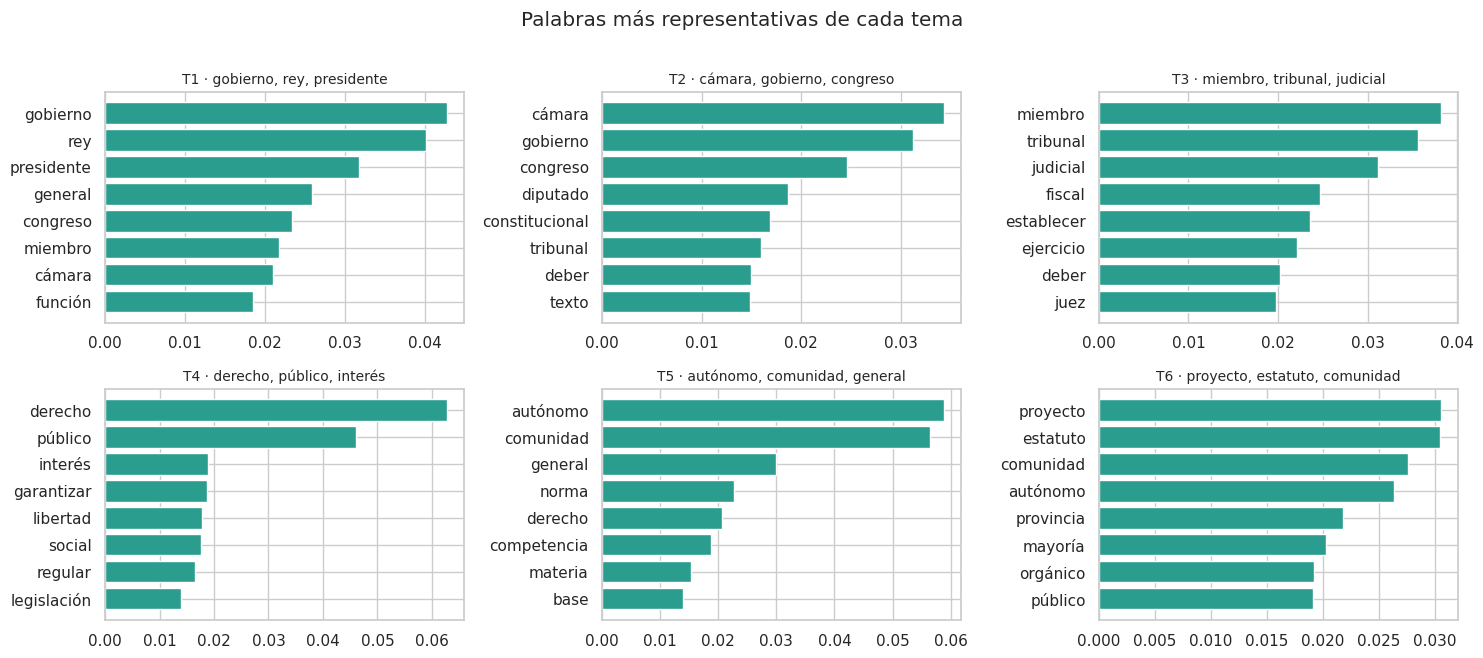

In [52]:
LEGAL_STOP = ["artículo", "constitución", "español", "españa", "apartado", "previsto", "caso", "ley"]
vectorizer = CountVectorizer(min_df=3, max_df=0.5, stop_words=LEGAL_STOP, token_pattern=r"(?u)\b\w{2,}\b")
docs_lda = df["processed_tokens"].apply(" ".join)
X = vectorizer.fit_transform(docs_lda)
vocab = np.array(vectorizer.get_feature_names_out())
print(f"Matriz documento-término: {X.shape[0]} documentos × {X.shape[1]} términos")

N_TOPICS = 6
lda = LatentDirichletAllocation(n_components=N_TOPICS, learning_method="batch", max_iter=80, random_state=SEED,
                                doc_topic_prior=0.1, topic_word_prior=0.05).fit(X)
doc_topic = lda.transform(X)
topic_word = lda.components_ / lda.components_.sum(axis=1, keepdims=True)

# Etiqueta del tema = sus 3 palabras más representativas
topic_labels = {k: f"T{k + 1} · " + ", ".join(vocab[topic_word[k].argsort()[::-1][:3]]) for k in range(N_TOPICS)}
display(pd.Series({topic_labels[k]: ", ".join(vocab[topic_word[k].argsort()[::-1][:10]]) for k in range(N_TOPICS)},
                  name="palabras clave (top 10)").to_frame())

df["topic_id"] = doc_topic.argmax(axis=1)
df["topic_label"] = df["topic_id"].map(topic_labels)
df["topic_prob"] = doc_topic.max(axis=1)

# ¿Qué títulos de la Constitución pesan en cada tema? (contraste con la estructura real del texto)
display((pd.crosstab(df["Fuente"], df["topic_label"], normalize="index").reindex(SOURCE_ORDER) * 100).round(0).astype(int))

fig, axes = plt.subplots(2, 3, figsize=(15, 6.5))
for k, ax in zip(range(N_TOPICS), axes.ravel()):
    idx = topic_word[k].argsort()[::-1][:8]
    ax.barh(vocab[idx][::-1], topic_word[k][idx][::-1], color="#2a9d8f"); ax.set_title(topic_labels[k], fontsize=10)
plt.suptitle("Palabras más representativas de cada tema", y=1.01); plt.tight_layout(); plt.show()

In [55]:
N_TOPICS = 8
print("Número de temas elegido:", N_TOPICS)

# priores dispersos (alpha, eta bajos): textos cortos con 1-3 temas por comentario
lda = LatentDirichletAllocation(n_components=N_TOPICS, learning_method="batch", max_iter=80, random_state=SEED,
                                doc_topic_prior=0.1, topic_word_prior=0.05).fit(X)
doc_topic = lda.transform(X)
topic_word = lda.components_ / lda.components_.sum(axis=1, keepdims=True)

def label_topic(k):
    score = {a: sum(topic_word[k, vocab_idx[w]] for w in lemmas if w in vocab_idx) for a, lemmas in ASPECT_LEMMAS.items()}
    best = sorted(score.items(), key=lambda kv: kv[1], reverse=True)[:2]
    names = [a for a, s in best if s > 0.02]
    return f"T{k + 1} · " + (" / ".join(names) if names else "valoración general")


topic_labels = {k: label_topic(k) for k in range(N_TOPICS)}
top_words = {topic_labels[k]: ", ".join(vocab[topic_word[k].argsort()[::-1][:10]]) for k in range(N_TOPICS)}
display(pd.Series(top_words, name="palabras clave (top 10)").to_frame())

Número de temas elegido: 8


,palabras clave (top 10)
T1 · valoración general,"rey, gobierno, general, presidente, cortes, congreso, presupuesto, ejercer, confianza, edad"
T2 · valoración general,"tribunal, gobierno, determinar, orgánico, cámara, órgano, congreso, comunidad, autónomo, excepción"
T3 · valoración general,"miembro, tribunal, judicial, fiscal, constitucional, gobierno, establecer, función, presidente, propuesta"
T4 · valoración general,"público, comunidad, autónomo, derecho, interés, general, económico, garantizar, legislación, social"
T5 · valoración general,"general, cámara, base, estatuto, norma, autónomo, comunidad, título, materia, legislativo"
T6 · valoración general,"mayoría, cámara, proyecto, congreso, absoluto, estatuto, aprobar, orgánico, plazo, miembro"
T7 · valoración general,"autónomo, comunidad, respectivo, elección, provincia, estatuto, senador, año, diputado, efecto"
T8 · valoración general,"derecho, libertad, ejercicio, regular, establecer, público, deber, social, reconocido, garantizar"


In [54]:
df["topic_id"] = doc_topic.argmax(axis=1)
df["topic_label"] = df["topic_id"].map(topic_labels)
df["topic_prob"] = doc_topic.max(axis=1)

# Lectura de negocio: peso del tema y sentimiento dominante de sus comentarios
temas = (df.groupby("topic_label").agg(comentarios=("ID", "size"), pct_neg=("sentiment_label", lambda s: (s == "NEG").mean() * 100),
                                       pct_pos=("sentiment_label", lambda s: (s == "POS").mean() * 100),
                                       polaridad=("polarity", "mean")).round(1))
temas["lectura"] = np.where(temas["pct_neg"] >= 50, "Punto débil", np.where(temas["pct_pos"] >= 50, "Fortaleza", "Mixto"))
display(temas.sort_values("comentarios", ascending=False))

fig, axes = plt.subplots(2, int(np.ceil(N_TOPICS / 2)), figsize=(4.2 * int(np.ceil(N_TOPICS / 2)), 6.5))
for k, ax in zip(range(N_TOPICS), axes.ravel()):
    idx = topic_word[k].argsort()[::-1][:8]
    ax.barh(vocab[idx][::-1], topic_word[k][idx][::-1], color="#2a9d8f")
    ax.set_title(topic_labels[k], fontsize=10)
for ax in axes.ravel()[N_TOPICS:]:
    ax.axis("off")
plt.suptitle("Palabras más representativas de cada tema", y=1.01); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.heatmap(pd.crosstab(df["Producto"], df["topic_label"], normalize="index").reindex(PRODUCT_ORDER) * 100, annot=True, fmt=".0f",
            cmap="YlGnBu", cbar=False, ax=axes[0]); axes[0].set_title("Peso de cada tema por producto (%)")
sns.heatmap(pd.crosstab(df["Fuente"], df["topic_label"], normalize="index").reindex(SOURCE_ORDER) * 100, annot=True, fmt=".0f",
            cmap="YlGnBu", cbar=False, ax=axes[1]); axes[1].set_title("Peso de cada tema por fuente (%)")
for ax in axes:
    ax.set_xlabel(""); ax.set_ylabel(""); ax.tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.show()

KeyError: "Column(s) ['polarity', 'sentiment_label'] do not exist"

### 2.4 Sentimiento por aspecto (opcional avanzado)

Se desarrolla tras el NER porque **reutiliza las entidades `CARACTERISTICA` / `SERVICIO`**: cada comentario se parte en **segmentos** (por `. ; ! ?` y conectores adversativos *pero, aunque, sin embargo, eso sí*), y el sentimiento de cada aspecto es el del **segmento donde aparece**. Así un comentario como *"el sonido es genial, pero el ajuste es pésimo"* aporta un aspecto positivo y otro negativo, en vez de una única etiqueta global.

In [ ]:
SEG_RE = re.compile(r"[.;!?¡¿]+|\b(?:pero|aunque|sin embargo|eso sí)\b", re.I)


def split_segments(text):
    spans, start = [], 0
    for m in SEG_RE.finditer(text):
        if text[start:m.start()].strip():
            spans.append((start, m.start()))
        start = m.end()
    if text[start:].strip():
        spans.append((start, len(text)))
    return spans


rows = []
for idx, doc in enumerate(docs_ner):
    spans = split_segments(doc.text)
    for ent in doc.ents:
        if ent.label_ not in ("CARACTERISTICA", "SERVICIO"):
            continue
        k = next((i for i, (s, e) in enumerate(spans) if s <= ent.start_char < e), None)
        if k is not None:
            rows.append((idx, ent.ent_id_, ent.label_, ent.text.lower(), k, doc.text[spans[k][0]:spans[k][1]].strip(" ,:")))
asp = (pd.DataFrame(rows, columns=["row", "aspecto", "tipo", "termino", "seg_id", "segmento"])
       .drop_duplicates(["row", "aspecto", "seg_id"]))

# Sentimiento por segmento único (evita inferencias repetidas)
unique_segments = asp["segmento"].unique().tolist()
seg_sent = dict(zip(unique_segments, predict_sentiment(unique_segments)))
asp["sent_label"] = asp["segmento"].map(lambda s: seg_sent[s][0])
asp["polarity"] = asp["segmento"].map(lambda s: seg_sent[s][1] - seg_sent[s][3])
asp = asp.join(df[["ID", "Fuente", "Producto", "Puntuacion"]], on="row")

by_row = asp.groupby("row")[["aspecto", "sent_label"]].apply(lambda g: list(zip(g["aspecto"], g["sent_label"])))
df["aspectos"] = [by_row.get(i, []) for i in range(len(df))]
print(f"{len(asp)} menciones de aspecto en {asp['row'].nunique()} de {len(df)} comentarios")
display(asp[["ID", "Producto", "aspecto", "segmento", "sent_label", "polarity"]].sample(8, random_state=SEED))

In [ ]:
def aspect_table(a):
    """Tabla POS/NEU/NEG por aspecto + % y sentimiento neto = (POS − NEG) / menciones."""
    t = (a.groupby(["aspecto", "sent_label"]).size().unstack(fill_value=0).reindex(columns=SENT_ORDER, fill_value=0))
    t["menciones"] = t[SENT_ORDER].sum(axis=1)
    t["%POS"] = (t["POS"] / t["menciones"] * 100).round(1)
    t["%NEG"] = (t["NEG"] / t["menciones"] * 100).round(1)
    t["neto"] = ((t["POS"] - t["NEG"]) / t["menciones"]).round(2)
    return t.sort_values("menciones", ascending=False)


display(aspect_table(asp[asp["tipo"] == "CARACTERISTICA"]))

fig, ax = plt.subplots(figsize=(11, 4.5))
tab = (asp[asp["tipo"] == "CARACTERISTICA"].groupby(["aspecto", "sent_label"]).size().unstack(fill_value=0)
       .reindex(columns=SENT_ORDER, fill_value=0))
tab = tab.loc[tab.sum(axis=1).sort_values().index]
tab.plot(kind="barh", stacked=True, color=[SENT_COLORS[c] for c in SENT_ORDER], ax=ax, width=.75)
ax.set_title("Menciones de cada característica y su sentimiento (todos los productos y fuentes)"); ax.set_ylabel("")
ax.legend(title="", frameon=False)
plt.tight_layout(); plt.show()

## Fase 3 — Información para la toma de decisiones y reporte gerencial

### 3.1 Preguntas decisionales (Goldratt)

Goldratt distingue **datos** de **información**: información es *la respuesta a la pregunta que se hace el decisor*. Por eso, antes de graficar nada, fijamos una pregunta concreta por cada desafío estratégico, con **qué se mide, sobre qué datos y para qué decisión**:

| # | Desafío | Pregunta decisional |
|---|---|---|
| **P1** | Rediseño del producto | ¿Cuáles son las **3 características más mencionadas con sentimiento positivo predominante** y las **3 deficiencias más mencionadas con sentimiento negativo predominante** en los auriculares TecnoGadget (reseñas de Amazon, ForoX y X), que deban conservarse o corregirse en el próximo modelo? |
| **P2** | Optimización del servicio | ¿Cuáles son los **3 puntos de dolor más frecuentes** (tiempos de espera, atención, garantía, chatbot...) en las interacciones con el servicio técnico y **cuántos puntos de satisfacción cuestan**, y qué **defectos del producto** originan más contactos, para priorizar mejoras que suban la satisfacción y reduzcan costes? |
| **P3** | Análisis competitivo | ¿En qué **dimensiones** (calidad del producto, funcionalidades, relación calidad-precio) y **aspectos** el sentimiento neto de TecnoGadget está **por encima o por debajo** del mejor de sus dos competidores, y dónde debe actuar para cerrar la brecha? |

In [ ]:
QUESTIONS = {
    "P1": "¿Qué 3 características conservar y qué 3 deficiencias corregir en el rediseño?",
    "P2": "¿Cuáles son los 3 puntos de dolor del servicio técnico y cuánta satisfacción cuestan?",
    "P3": "¿Dónde está TecnoGadget por encima/por debajo de sus competidores?",
}
MIN_MENTIONS = 10          # umbral para no sacar conclusiones de aspectos con muy pocas menciones
CARAC = asp[asp["tipo"] == "CARACTERISTICA"]
RESENAS = CARAC[CARAC["Fuente"] != "ServicioCliente"]      # P1 y P3 usan solo reseñas (el servicio solo atiende a TecnoGadget)

### 3.2 P1 — Rediseño del producto

In [ ]:
q1 = aspect_table(RESENAS[RESENAS["Producto"] == PRODUCT_TG])
q1 = q1[q1["menciones"] >= MIN_MENTIONS]
fortalezas = q1[q1["POS"] > q1["NEG"]].head(3)          # ya ordenado por menciones
deficiencias = q1[q1["NEG"] > q1["POS"]].head(3)
display(q1.style.background_gradient(subset=["neto"], cmap="RdYlGn", vmin=-1, vmax=1))

plot_q1 = q1.sort_values("menciones")
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.barh(plot_q1.index, plot_q1["POS"], color=SENT_COLORS["POS"], label="Positivas")
ax.barh(plot_q1.index, -plot_q1["NEG"], color=SENT_COLORS["NEG"], label="Negativas")
for i, (a, r) in enumerate(plot_q1.iterrows()):
    if a in fortalezas.index or a in deficiencias.index:
        ax.text(0, i, "  ★" if a in fortalezas.index else "  ✖", va="center", ha="left" if a in fortalezas.index else "right", fontsize=11)
ax.axvline(0, color="black", lw=.8)
ax.set_title("TecnoGadget: menciones positivas (→) y negativas (←) por característica   ★ conservar · ✖ corregir")
ax.legend(frameon=False, loc="lower right"); plt.tight_layout(); plt.show()


def fmt(tab):
    return "; ".join(f"**{a}** ({int(r['menciones'])} menciones, {r['%POS']:.0f}% pos. / {r['%NEG']:.0f}% neg.)" for a, r in tab.iterrows())


display(Markdown(f"**Respuesta a P1.** Conservar: {fmt(fortalezas)}.  \nCorregir: {fmt(deficiencias)}."))

### 3.3 P2 — Optimización del servicio al cliente

In [ ]:
svc = df[df["Fuente"] == "ServicioCliente"]
svc_asp = asp[asp["Fuente"] == "ServicioCliente"]

rows = []
for a in SERVICE_ASPECTS:
    ids = set(svc_asp[(svc_asp["aspecto"] == a) & (svc_asp["sent_label"] == "NEG")]["ID"])
    con, sin = svc[svc["ID"].isin(ids)], svc[~svc["ID"].isin(ids)]
    rows.append({"punto de dolor": a, "interacciones con queja": len(ids), "% de interacciones": len(ids) / len(svc) * 100,
                 "satisfacción (con queja)": con["Puntuacion"].mean(), "satisfacción (resto)": sin["Puntuacion"].mean()})
q2 = pd.DataFrame(rows).set_index("punto de dolor")
q2["puntos perdidos"] = q2["satisfacción (resto)"] - q2["satisfacción (con queja)"]
q2 = q2.sort_values("interacciones con queja", ascending=False)
display(q2.round(2))

causas = (svc_asp[(svc_asp["tipo"] == "CARACTERISTICA") & (svc_asp["sent_label"] == "NEG")]
          .groupby("aspecto")["ID"].nunique().sort_values(ascending=False).rename("interacciones"))
causas_pct = (causas / len(svc) * 100).round(1).rename("% de interacciones")
display(pd.concat([causas, causas_pct], axis=1).T)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
q2["interacciones con queja"].sort_values().plot(kind="barh", color="#e76f51", ax=axes[0]); axes[0].set_title("Interacciones con queja por punto de dolor")
q2[["satisfacción (con queja)", "satisfacción (resto)"]].plot(kind="bar", color=["#e76f51", "#2a9d8f"], ax=axes[1], rot=20)
axes[1].set_title("Satisfacción media (1-5): con queja vs. resto"); axes[1].set_xlabel(""); axes[1].legend(frameon=False)
causas.sort_values().plot(kind="barh", color="#264653", ax=axes[2]); axes[2].set_title("Defecto del producto que motiva el contacto")
plt.tight_layout(); plt.show()

top_pain = q2.head(3)
pain_txt = "; ".join(f"**{a}** ({int(r['interacciones con queja'])} interacciones, {r['% de interacciones']:.0f}% del total, −{r['puntos perdidos']:.1f} pts)"
                     for a, r in top_pain.iterrows())
cause_txt = ", ".join(f"**{a}** ({v})" for a, v in causas.head(3).items())
display(Markdown(f"**Respuesta a P2.** Puntos de dolor: {pain_txt}.  \nDefectos que más contactos generan: {cause_txt}. "
                 f"Satisfacción media del servicio: **{svc['Puntuacion'].mean():.2f}/5** "
                 f"({(svc['sentiment_label'] == 'NEG').mean() * 100:.0f}% de interacciones con sentimiento negativo)."))

### 3.4 P3 — Análisis competitivo

In [ ]:
def net_sentiment(s):
    return ((s == "POS").sum() - (s == "NEG").sum()) / len(s)


counts = RESENAS.groupby(["aspecto", "Producto"]).size().unstack(fill_value=0).reindex(columns=PRODUCT_ORDER, fill_value=0)
net = RESENAS.groupby(["aspecto", "Producto"])["sent_label"].agg(net_sentiment).unstack().reindex(columns=PRODUCT_ORDER)
net = net[(counts >= MIN_MENTIONS).all(axis=1)]
net["brecha vs. mejor competidor"] = net[PRODUCT_TG] - net[[PRODUCT_A, PRODUCT_B]].max(axis=1)
net = net.sort_values("brecha vs. mejor competidor", ascending=False)

RESENAS = RESENAS.assign(dimension=RESENAS["aspecto"].map({a: d for d, aa in DIMENSIONES.items() for a in aa}))
dim_net = RESENAS.groupby(["dimension", "Producto"])["sent_label"].agg(net_sentiment).unstack().reindex(columns=PRODUCT_ORDER)
dim_net["brecha vs. mejor competidor"] = dim_net[PRODUCT_TG] - dim_net[[PRODUCT_A, PRODUCT_B]].max(axis=1)
display(dim_net.rename(columns=BRAND_SHORT).round(2))

resumen = (df[df["Fuente"] != "ServicioCliente"].groupby("Producto").agg(
    comentarios=("ID", "size"), puntuacion_media=("Puntuacion", "mean"),
    pct_pos=("sentiment_label", lambda s: (s == "POS").mean() * 100),
    pct_neg=("sentiment_label", lambda s: (s == "NEG").mean() * 100)).round(2).reindex(PRODUCT_ORDER))
display(resumen)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
sns.heatmap(net[PRODUCT_ORDER].rename(columns=BRAND_SHORT), annot=True, fmt=".2f", cmap="RdYlGn", center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Sentimiento neto por aspecto y producto (−1 negativo · +1 positivo)"); axes[0].set_ylabel(""); axes[0].set_xlabel("")
gap = net["brecha vs. mejor competidor"].sort_values()
gap.plot(kind="barh", color=np.where(gap >= 0, SENT_COLORS["POS"], SENT_COLORS["NEG"]), ax=axes[1])
axes[1].axvline(0, color="black", lw=.8); axes[1].set_title("Brecha de TecnoGadget vs. el mejor competidor"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

TH = 0.10
ventajas, desventajas = net[net["brecha vs. mejor competidor"] >= TH], net[net["brecha vs. mejor competidor"] <= -TH]
fmt_gap = lambda t: ", ".join(f"**{a}** ({r['brecha vs. mejor competidor']:+.2f})" for a, r in t.iterrows()) or "ninguno"
display(Markdown(f"**Respuesta a P3.** TecnoGadget lidera en: {fmt_gap(ventajas)}.  \nVa por detrás en: {fmt_gap(desventajas.sort_values('brecha vs. mejor competidor'))}.  \n"
                 f"Dimensión más débil frente a la competencia: **{dim_net['brecha vs. mejor competidor'].idxmin()}** "
                 f"({dim_net['brecha vs. mejor competidor'].min():+.2f})."))

### 3.5 Prototipo de reporte gerencial

Mini-dashboard de **una sola página** con la respuesta a las tres preguntas, seguido del resumen ejecutivo. Se muestra **solo la información clave** (nada de datos brutos) para evitar el "síndrome del pajar".

In [ ]:
fig = plt.figure(figsize=(20, 10.5))
gs = GridSpec(2, 3, height_ratios=[.11, 1], hspace=.2, wspace=.38)
fig.suptitle("TecnoGadget S.A. — Voz del Cliente: panel para Producto y Marketing", fontsize=18, fontweight="bold", y=.995)

rev_tg = df[(df["Producto"] == PRODUCT_TG) & (df["Fuente"] != "ServicioCliente")]
kpis = [("Comentarios analizados", f"{len(df):,}"),
        ("Satisfacción reseñas TecnoGadget", f"{rev_tg['Puntuacion'].mean():.2f} / 5"),
        ("Reseñas TecnoGadget negativas", f"{(rev_tg['sentiment_label'] == 'NEG').mean() * 100:.0f}%"),
        ("Satisfacción del servicio", f"{svc['Puntuacion'].mean():.2f} / 5")]
kax = fig.add_subplot(gs[0, :]); kax.axis("off")
for i, (label, value) in enumerate(kpis):
    x = .02 + i * .25
    kax.text(x, .45, value, fontsize=26, fontweight="bold", color="#264653", transform=kax.transAxes)
    kax.text(x, .0, label, fontsize=12, color="#555", transform=kax.transAxes)

ax1 = fig.add_subplot(gs[1, 0])
ax1.barh(plot_q1.index, plot_q1["POS"], color=SENT_COLORS["POS"]); ax1.barh(plot_q1.index, -plot_q1["NEG"], color=SENT_COLORS["NEG"])
ax1.axvline(0, color="black", lw=.8); ax1.set_title("P1 · Qué conservar (★) y qué corregir (✖)", fontsize=13, loc="left")
for i, a in enumerate(plot_q1.index):
    if a in fortalezas.index: ax1.text(0, i, "  ★", va="center", fontsize=12)
    if a in deficiencias.index: ax1.text(0, i, "✖  ", va="center", ha="right", fontsize=12)

ax2 = fig.add_subplot(gs[1, 1])
pain = q2.sort_values("interacciones con queja")
ax2.barh(pain.index, pain["% de interacciones"], color="#e76f51")
for i, (a, r) in enumerate(pain.iterrows()):
    ax2.text(r["% de interacciones"] + .5, i, f"−{r['puntos perdidos']:.1f} pts", va="center", fontsize=10)
ax2.set_title("P2 · % de interacciones con queja (y satisfacción perdida)", fontsize=13, loc="left"); ax2.set_xlim(0, pain["% de interacciones"].max() * 1.25)

ax3 = fig.add_subplot(gs[1, 2])
sns.heatmap(net[PRODUCT_ORDER].rename(columns=BRAND_SHORT), annot=True, fmt=".2f", cmap="RdYlGn", center=0, vmin=-1, vmax=1, cbar=False, ax=ax3)
ax3.set_title("P3 · Sentimiento neto vs. competidores", fontsize=13, loc="left"); ax3.set_xlabel(""); ax3.set_ylabel("")
fig.savefig("Dashboard_TecnoGadget.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
ACTIONS = {
    "sonido": "Mantener la firma sonora como eje de la comunicación de marca.",
    "graves": "Mantener; valorar un modo de realce de graves en la app.",
    "cancelación de ruido": "Proteger el ANC como diferencial y reforzarlo en la comunicación frente a la competencia.",
    "batería": "Conservar la autonomía y comunicarla; vigilar la degradación a medio plazo.",
    "comodidad y ajuste": "Rediseñar almohadillas y sujeción (más tallas/aletas) y validar con pruebas ergonómicas de uso prolongado.",
    "conectividad": "Auditar el firmware y el chip Bluetooth, reforzar el QA de emparejamiento y priorizar una actualización OTA.",
    "micrófono": "Mejorar el array de micrófonos y la reducción de viento/eco en la próxima iteración.",
    "app y ecualizador": "Conservar el ecualizador; estabilizar la app (errores y pérdida de perfiles) si hay quejas.",
    "diseño y estuche": "Revisar materiales y bisagra del estuche (resistencia a arañazos y desgaste).",
    "precio": "Revisar posicionamiento de precio o reforzar el valor percibido (accesorios, garantía ampliada).",
    "tiempos de espera": "Fijar un SLA de respuesta, ampliar horario/capacidad y ofrecer devolución de llamada.",
    "garantía y devoluciones": "Simplificar el proceso de garantía: recogida a cargo de la empresa y sustitución anticipada.",
    "atención del agente": "Formación en resolución en primer contacto, guiones menos rígidos y escalado rápido.",
    "chatbot": "Mejorar la derivación a un humano y reducir bucles de menú en el asistente virtual.",
}
act = lambda names: "\n".join(f"- **{a}**: {ACTIONS.get(a, 'Analizar con el equipo responsable.')}" for a in names)

resumen_md = f"""
## Resumen ejecutivo para la gerencia de TecnoGadget S.A.

**Contexto.** Se han analizado {len(df):,} comentarios (reseñas de {', '.join(SOURCE_ORDER[:3])} y transcripciones de servicio) con PLN:
sentimiento, entidades, temas y sentimiento por aspecto.

**1 · Producto (P1).** Los clientes valoran sobre todo {', '.join(f'**{a}**' for a in fortalezas.index)}.
Las deficiencias dominantes son {', '.join(f'**{a}**' for a in deficiencias.index)}.

**2 · Servicio (P2).** Los mayores puntos de dolor son {', '.join(f'**{a}**' for a in top_pain.index)}; los defectos del producto que más contactos
generan son {', '.join(f'**{a}**' for a in causas.head(3).index)}. Corregir el producto reduce también la carga del servicio.

**3 · Competencia (P3).** Ventaja frente al mejor competidor en {', '.join(f'**{a}**' for a in ventajas.index) or 'ningún aspecto'};
desventaja en {', '.join(f'**{a}**' for a in desventajas.index) or 'ningún aspecto'}.

### Recomendaciones accionables
**Conservar y comunicar**
{act(fortalezas.index)}

**Corregir en el próximo modelo**
{act(deficiencias.index)}

**Mejorar el servicio**
{act(top_pain.index)}

**Cerrar brechas competitivas**
{act(desventajas.index.difference(deficiencias.index))}
"""
display(Markdown(resumen_md))

### 3.6 Reflexión crítica sobre la calidad de la información (Goldratt)

- **¿Responde a la pregunta del gerente?** Cada panel contesta una pregunta cerrada (qué conservar/corregir, qué duele más en el servicio, dónde estamos por encima o por debajo). No se entregan listados, sino rankings con umbral mínimo de menciones.
- **Validez del sentimiento**: el modelo es general (no conoce el dominio) y se ha contrastado con las estrellas; el acuerdo no es perfecto porque hay comentarios mixtos y puntuaciones con ruido. El sentimiento por **aspecto** mejora esa limitación al evaluar el segmento concreto.
- **Límites del enfoque por segmentos**: separar por puntuación y conectores no resuelve ironía, referencias cruzadas ni aspectos implícitos (p. ej. *"se me caen al correr"* sin nombrar el ajuste). La taxonomía es manual y habría que mantenerla.
- **NER**: el modelo pequeño de spaCy comete falsos positivos en texto corto y en minúsculas; se mitiga con el `EntityRuler` para el dominio y con una capa de validación, pero la cobertura de personas y lugares sigue siendo orientativa.
- **LDA**: los temas son una ayuda exploratoria; con textos cortos y cercanos a la taxonomía acaban coincidiendo con los aspectos. Su valor está en descubrir temas **no previstos** (en datos reales aparecerían quejas fuera de la taxonomía).
- **Datos simulados**: los resultados **confirman** los perfiles introducidos en la simulación, pero no son evidencia sobre un mercado real. Con datos reales habría que revisar sesgo de muestreo (quien reseña suele estar muy contento o muy enfadado) y la representatividad de cada canal.

### 3.7 Exportación de entregables

In [ ]:
final = df.drop(columns=["raw_tokens", "raw_length"]).copy()
for col in ["processed_tokens", "entidades", "aspectos"]:
    final[col] = final[col].apply(lambda v: json.dumps(v, ensure_ascii=False))
final.to_csv("Datos_TecnoGadget_analizado.csv", index=False, encoding="utf-8")
asp.drop(columns=["row", "seg_id"]).to_csv("Aspectos_TecnoGadget.csv", index=False, encoding="utf-8")

display(final.drop(columns=["texto_limpio", "processed_tokens"]).head(5))
print("Columnas del DataFrame final:", final.columns.tolist())

try:                                    # descarga automática solo en Colab
    from google.colab import files
    for f in ["Datos_TecnoGadget.csv", "Datos_TecnoGadget_analizado.csv", "Dashboard_TecnoGadget.png"]:
        files.download(f)
except ImportError:
    pass